# Results and Plots

The previous notebooks looked at single results, mostly capacities and yearly operation from the optimization summaries. This notebook gives an overview of the results FINE provides after an optimization and how to plot them:

| Topic | Functions |
|---|---|
| Yearly results and costs | `esM.getOptimizationSummary` |
| Hourly results | `getOptimalValues` of a modeling class |
| Electricity prices | `fn.getShadowPrices` |
| Plots | `fn.plotOperation`, `fn.plotOperationColorMap`, `fn.plotLocationalColorMap`, `fn.plotTransmission`, `fn.plotLocations` |

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import fine as fn
from tutorialHelpers import COLORS, DATA_PATH, buildBasicTutorialModel, colormap

warnings.filterwarnings("ignore")  # keeps the output of this tutorial readable

In [2]:
esM = buildBasicTutorialModel()
esM.aggregateTemporally(n_clusters=8, segments=None)
esM.optimize(timeSeriesAggregation=True)

Set parameter OutputFlag to value 1


Set parameter Threads to value 3


Set parameter LogFile to value ""


Set parameter QCPDual to value 1


Gurobi Optimizer version 13.0.1 build v13.0.1rc0 (win64 - Windows 11+.0 (26300.2))


CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]


... (71 outputs left out)

Solved with barrier


    3402    5.9738972e+05   0.000000e+00   0.000000e+00      1s


Solved in 3402 iterations and 0.69 seconds (0.88 work units)


Optimal objective  5.973897241e+05


## 1. Optimization summaries

FINE groups the components into **modeling classes**, one per component type. The optimization summary is a table per modeling class and investment period:

In [3]:
list(esM.componentModelingDict)

['SourceSinkModel', 'ConversionModel', 'StorageModel', 'TransmissionModel']

`outputLevel` sets how much of the summary is shown: `0` shows everything, `1` drops rows that are empty (NaN), `2` also drops rows that are 0 everywhere. The rows are component, property and unit; the columns are the regions (for transmissions, the columns are the destinations and the index has an additional level with the origin). These are the properties of the gas power plants in 2040:

In [4]:
esM.getOptimizationSummary("ConversionModel", outputLevel=1, ip=2040).loc[
    "Gas power plants"
]

,,north,south
Property,Unit,,
NPVcontribution,[1e6 Euro],3946.072168,3677.175188
TAC,[1e6 Euro/a],2537.982302,2365.036712
capacity,[GW_el],32.647969,30.42324
capexCap,[1e6 Euro/a],1885.022926,1756.571912
commissioning,[GW_el],0.0,0.0
decommissioning,[GW_el],0.0,0.0
invest,[1e6 Euro],0.0,0.0
investLifetimeExtension,[1e6 Euro],0.0,0.0
operation,[GW_el*h],28133.593136,31567.899401


The properties fall into three groups:

- **Design**: `capacity` (everything available in the period), `commissioning` (newly built), `decommissioning` (reaching the end of its lifetime), `invest` (investment of the capacity newly built in the period).
- **Operation**: `operation`, the yearly sum of the operation (for storages: charge, discharge and state of charge). With `hoursPerTimeStep=1`, it is also the energy in GWh.
- **Costs**: `TAC` is the total annual cost in the period, split into `capexCap` (annuity of the investment), `opexCap` (fixed operation cost), `opexOp` (cost per operation), `commodCosts` and `commodRevenues`. `NPVcontribution` is the contribution of the component to the objective value: its discounted cost over all years of the period.

The `NPVcontribution`s of all components and periods add up to the objective value:

In [5]:
totalNPV = 0
for modelingClass in esM.componentModelingDict:
    for year in esM.investmentPeriodNames:
        summary = esM.getOptimizationSummary(modelingClass, outputLevel=1, ip=year)
        npv = summary.xs("NPVcontribution", level="Property")
        totalNPV += npv.sum().sum()

pd.Series(
    {"Sum of NPVcontribution": totalNPV, "esM.objectiveValue": esM.objectiveValue}
).round(0)

Sum of NPVcontribution    597390.0
esM.objectiveValue        597390.0
dtype: float64

This makes the NPV contributions useful to see which components cause which part of the total cost. Here they are per component, both regions and all periods added up:

<Axes: xlabel='Contribution to the total cost [billion Euro]'>

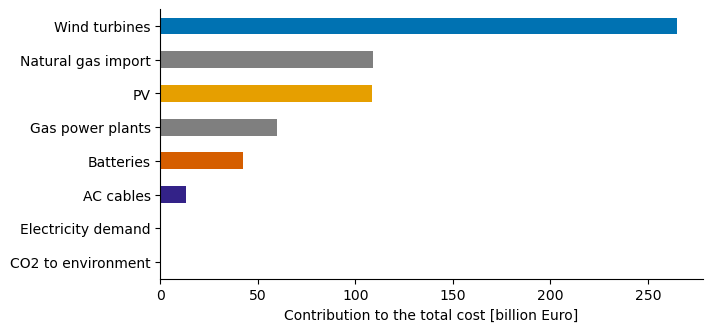

In [6]:
npvPerComponent = {}
for modelingClass in esM.componentModelingDict:
    for year in esM.investmentPeriodNames:
        summary = esM.getOptimizationSummary(modelingClass, outputLevel=1, ip=year)
        npv = summary.xs("NPVcontribution", level="Property").sum(axis=1)
        for component, value in npv.groupby(level="Component").sum().items():
            npvPerComponent[component] = npvPerComponent.get(component, 0) + value

npvPerComponent = pd.Series(npvPerComponent).sort_values() / 1000  # billion Euro
npvPerComponent.plot.barh(
    color=[COLORS[c] for c in npvPerComponent.index],
    xlabel="Contribution to the total cost [billion Euro]",
    figsize=(7, 3.5),
)

The wind turbines cause the largest part of the total cost, followed by the natural gas and the PV. The sinks cause no cost, since neither the demand nor the CO<sub>2</sub> emissions have a price in this model.

## 2. Hourly results

The hourly results are stored in the modeling classes. `getOptimalValues` returns them for one investment period as a dictionary, whose entry `"values"` is a `pd.DataFrame` with one row per component and region and one column per hour of the year. Although the optimization used 8 typical days, the results are given for all 8760 hours: every day takes the values of its typical day.

The names of the variables are those of the `variableName` parameter of the plotting functions: `"operationVariablesOptimum"` for the operation of sources, sinks, conversions and transmissions; `"chargeOperationVariablesOptimum"`, `"dischargeOperationVariablesOptimum"` and `"stateOfChargeOperationVariablesOptimum"` for storages.

In [7]:
sourceSinkOperation = esM.componentModelingDict["SourceSinkModel"].getOptimalValues(
    "operationVariablesOptimum", ip=2040
)["values"]
conversionOperation = esM.componentModelingDict["ConversionModel"].getOptimalValues(
    "operationVariablesOptimum", ip=2040
)["values"]

sourceSinkOperation.iloc[:, :6].round(1)

time                            0     1     2     3     4     5
component          location                                    
CO2 to environment north      0.0   0.0   0.0   0.0   0.0   0.0
                   south      0.0   0.0   0.0   0.0   0.0   0.0
Electricity demand north     41.1  39.7  38.5  37.0  32.9  35.0
                   south     31.0  29.0  28.4  27.0  26.1  25.4
Natural gas import north      0.0   0.0   0.0   0.0   0.0   0.0
                   south      0.0   0.0   0.0   0.0   0.0   0.0
PV                 north      0.0   0.0   0.0   0.0   0.0   0.0
                   south      0.0   0.0   0.0   0.0   0.0   0.0
Wind turbines      north     41.1  39.7  29.9  19.7  29.3  32.5
                   south     31.0  29.0  37.3  42.3  29.9  28.1

With these, we can draw the electricity supply of the north in a week of 2040. The generation of wind turbines, PV and gas power plants is stacked; the line is the demand. Where the generation is above the demand, the north charges batteries or sends electricity to the south; where it is below, it uses its batteries or imports from the south.

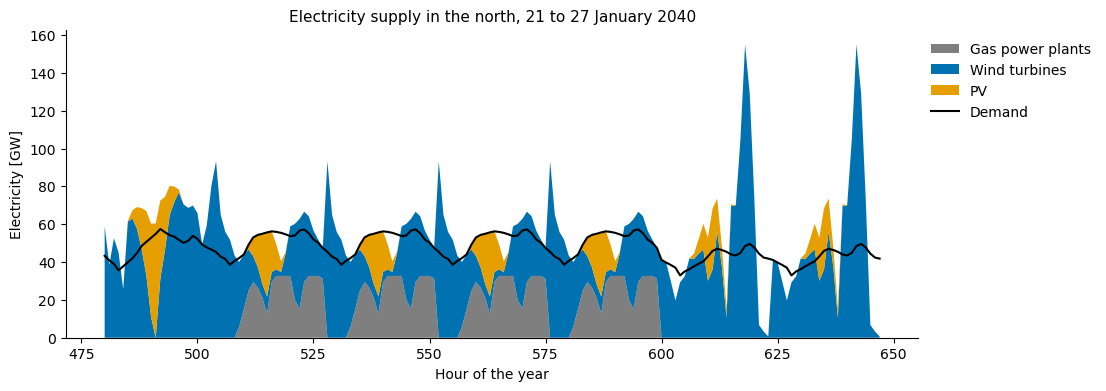

In [8]:
week = range(480, 648)  # 21 to 27 January
generators = ["Gas power plants", "Wind turbines", "PV"]
generation = pd.DataFrame(
    {
        "Gas power plants": conversionOperation.loc[("Gas power plants", "north")],
        "Wind turbines": sourceSinkOperation.loc[("Wind turbines", "north")],
        "PV": sourceSinkOperation.loc[("PV", "north")],
    }
).iloc[week]
demand = sourceSinkOperation.loc[("Electricity demand", "north")].iloc[week]

fig, ax = plt.subplots(figsize=(11, 4))
ax.stackplot(
    generation.index,
    generation.T,
    labels=generators,
    colors=[COLORS[c] for c in generators],
)
ax.plot(demand.index, demand, color=COLORS["Electricity demand"], label="Demand")
ax.set(
    title="Electricity supply in the north, 21 to 27 January 2040",
    xlabel="Hour of the year",
    ylabel="Electricity [GW]",
)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

Several days of this week look alike: with 8 typical days, they are represented by the same typical day. On the calm days in the middle of the week, the gas power plants cover a large part of the demand in the evening and at night. On the windy days at the end of the week, the wind turbines produce up to three times the demand of the north; the north sends the surplus to the south and charges its batteries.

## 3. Electricity prices from shadow prices

Every constraint of a linear optimization problem has a **shadow price** (dual value): how much the objective value would change if the constraint were relaxed by one unit. For the energy balance of electricity in a region and hour, this is the cost of supplying one more unit of electricity there and then, i.e. a price. `fn.getShadowPrices` reads them from the solved problem; the energy balances are the constraint `esM.pyM.commodityBalanceConstraint`. With typical days, `hasTimeSeries=True` together with `periodOccurrences` and `periodsOrder` turns them into a time series of all 8760 hours. Note that `ip` is the index of the investment period here (0, 1, 2), not the year.

In a model with several investment periods, the shadow prices are **discounted** values, because the objective value is the discounted total cost (FINE warns about this). To get prices in Euro per MWh for the years of a period, we divide by the discount factor of the period: the sum of the factors 1/(1+r)<sup>t</sup> of its years, counted from the start year. This is only this simple because all components of our model use the same interest rate r of 8 %.

In [9]:
interestRate = 0.08
years = esM.investmentPeriodInterval

prices = {}
for index, year in enumerate(esM.investmentPeriodNames):
    shadowPrices = fn.getShadowPrices(
        esM,
        esM.pyM.commodityBalanceConstraint,
        ip=index,
        hasTimeSeries=True,
        periodOccurrences=esM.periodOccurrences,
        periodsOrder=esM.periodsOrder,
    )
    firstYear = year - esM.startYear
    discountFactor = sum(
        1 / (1 + interestRate) ** t for t in range(firstYear, firstYear + years)
    )
    # million Euro per GWh = 1000 Euro per MWh
    prices[year] = shadowPrices.loc["electricity"] / discountFactor * 1000

prices = pd.DataFrame(prices)  # Euro per MWh, rows: region and hour
prices.groupby(level=0).mean().round(1)

,2020,2030,2040
north,111.2,119.7,170.9
south,116.5,130.6,173.4


The mean price per region and period in Euro per MWh. Sorted from the highest to the lowest hour, the prices of a year form a **price duration curve**:

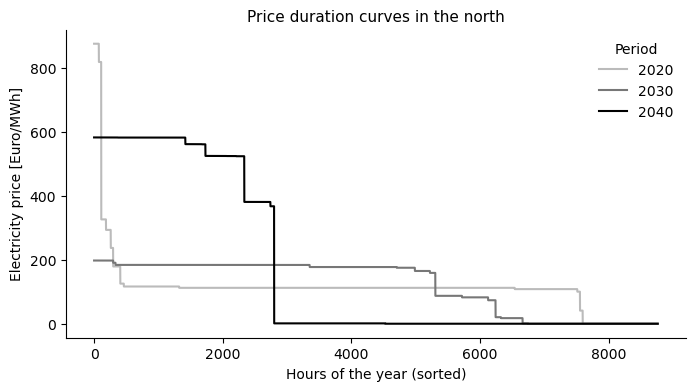

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for year, color in zip(esM.investmentPeriodNames, ["#BBBBBB", "#777777", "#000000"]):
    sortedPrices = np.sort(prices[year].loc["north"].to_numpy())[::-1]
    ax.plot(sortedPrices, color=color, label=year)
ax.set(
    xlabel="Hours of the year (sorted)",
    ylabel="Electricity price [Euro/MWh]",
    title="Price duration curves in the north",
)
ax.legend(title="Period")

The curves show how the prices change over the periods. In 2040, the price is close to zero in about two thirds of the hours: there is more wind and solar power than needed at that moment, so one more MWh costs nothing. In the other hours, the gas power plants run, and the price contains their fuel cost and the cost of the CO<sub>2</sub> limit, which is high in 2040, since only 20 million tonnes may be emitted.

## 4. Plotting functions of FINE

FINE has plotting functions for the most common views of the results. All of them take the model, the name of a component and the investment period `ip` (as a year), and return the matplotlib figure and axes, so that the plots can be changed further. The ones used in the notebooks so far:

| Function | Shows | Used in |
|---|---|---|
| `fn.plotOperation` | a time series of one component in one region as a line | [Storages](14_storages.ipynb) |
| `fn.plotOperationColorMap` | a time series as a heat map (day × hour) | [Basic Tutorial](01_basic_tutorial.ipynb) and others |
| `fn.plotLocations` | the regions of a shape file | [Basic Tutorial](01_basic_tutorial.ipynb) |
| `fn.plotTransmission` | the capacity of a transmission component on a map | [Transmissions](15_transmissions.ipynb) |

`variableName` selects the variable to plot, as in section 2. A part of the year is plotted with `tMin` and `tMax` in `fn.plotOperation`:

Text(0.5, 1.0, 'Batteries in the south, 1 to 7 July 2040')

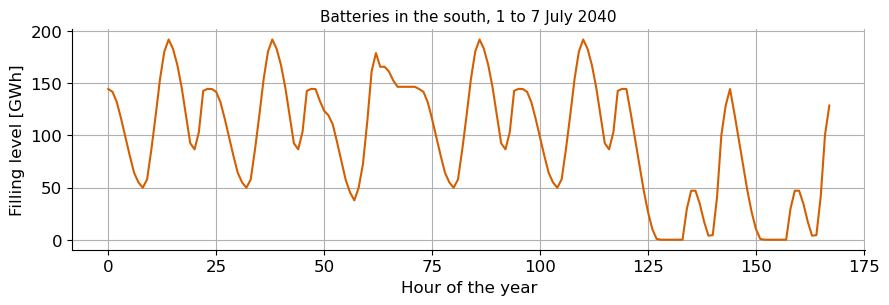

In [11]:
fig, ax = fn.plotOperation(
    esM,
    "Batteries",
    "south",
    ip=2040,
    variableName="stateOfChargeOperationVariablesOptimum",
    tMin=4344,  # 1 to 7 July
    tMax=4512,
    color=COLORS["Batteries"],
    xlabel="Hour of the year",
    ylabel="Filling level [GWh]",
    figsize=(9, 3),
)
ax.set_title("Batteries in the south, 1 to 7 July 2040")

**`fn.plotLocationalColorMap`** colors the regions of a map by a result of each region, by default the capacity. It needs a shape file of the regions and the name of its column with the region names (`indexColumn`). With `perArea=False`, it shows the capacity itself instead of the capacity per area:

Text(0.5, 1.0, 'Wind turbines in 2040')

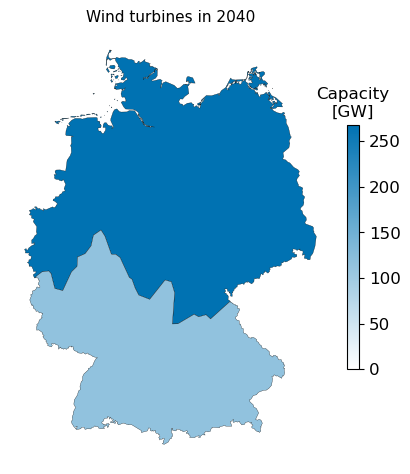

In [12]:
fig, ax = fn.plotLocationalColorMap(
    esM,
    "Wind turbines",
    DATA_PATH / "regions.geojson",
    indexColumn="region",
    ip=2040,
    perArea=False,
    cmap=colormap("Wind turbines"),
    zlabel="Capacity [GW]",
    figsize=(4, 5),
)
ax.set_title("Wind turbines in 2040")

## Things to try

- Plot the electricity supply of the south for the same week. Where does its electricity come from on calm days?
- Compute the electricity prices of the south and compare them with those of the north. In which hours do they differ, and why could that be?
- Plot the capacity of the PV with `fn.plotLocationalColorMap`, once with `perArea=False` and once with `perArea=True`.

The next notebook, [Balance Limits](41_balance_limits.ipynb), starts the part on advanced features with limits on the yearly balance of commodities.